# Basic Data Usage
This notebook provides a guide to loading and basic visualizatiuon and manipulation of the data products from McDaniel et al. (2024): "Legacy Analysis of Dark Matter Annihilation from the Milky Way Dwarf Spheroidal Galaxies with 14 Years of Fermi-LAT Data" paper.

the topics covered here are 

i) Load and plot the SED (i.e. likelihood in flux-energy space) for indiivdual dSphs.

ii) Convert the flux-energy likelihood to DM space for a given model

ii) Load and plot the precomputed DM TS profile for a stacked sample

iii) Construct a sample of blank field limits

iv) Plot TS vs $M_{\chi}$ for a stacked sample, with blank field containment bands

iv) Obtain upper limits from a given TS profile.

iv) Plot $<\sigma v>$ vs $M_{\chi}$ upper limits (ULs) for a stacked sample, with blank field containment bands



This implementation requires the iMinuit package be installed. Similar results can be obtained usng scipy minimization functios (e.g. minimize_scalar())

In [26]:
import os,sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.io import fits
import copy
from scipy import interpolate
from iminuit import Minuit

In [29]:
#Set paths. Current path assume this is run in the same directory storing the (fully extracted) dSphs and blank_fields directories
dSphs_csv_path = './'
dSphs_sed_path = './dSphs/SEDs/'
dSphs_TS_prof_path = './dSphs/TS_profiles/'

blank_field_csv_path = './'
blank_TS_prof_path = './blank_fields/TS_profiles/'




In [28]:
def setplot():
    '''Defines standard plot parameters'''
    
    fig = plt.figure(figsize=(3.5, 3), dpi=150)
    ax = plt.gca()
    ax.tick_params(direction='in', which='both', top=True, right=True)
    return ax, fig

def get_ylims(sed):
    ''' Automatically sets flux range for the sed likelihood plots'''
    
    
    fmin = np.log10(np.nanmin(sed['e2dnde_ul'])) - 0.5
    fmax = np.log10(np.nanmax(sed['e2dnde_ul'])) + 0.5
    fdelta = fmax - fmin
    if fdelta < 2.0:
        fmin -= 0.5 * (2.0 - fdelta)
        fmax += 0.5 * (2.0 - fdelta)

    return fmin, fmax

def plot_lnlscan(sed, **kwargs):
    '''Make plot of the SED likelihood profile (very similar to fermipy SEDPlotter method)'''
    
    ax = kwargs.pop('ax', plt.gca())
    llhcut = kwargs.pop('llhcut', -2.70)
    cmap = kwargs.pop('cmap', 'BuGn')
    cmap_trunc_lo = kwargs.pop('cmap_trunc_lo', None)
    cmap_trunc_hi = kwargs.pop('cmap_trunc_hi', None)

    ylim = kwargs.pop('ylim', None)

    if ylim is None:
        fmin, fmax = get_ylims(sed)
    else:
        fmin, fmax = np.log10(ylim)

    fluxEdges = np.arange(fmin, fmax, 0.01)
    fluxCenters = 0.5*(fluxEdges[1:] + fluxEdges[:-1])
    fbins = len(fluxCenters)
    llhMatrix = np.zeros((len(sed['e_ref']), fbins))

    # loop over energy bins
    for i in range(len(sed['e_ref'])):
        m = sed['norm_scan'][i] > 0
        e2dnde_scan = sed['norm_scan'][i][m] * sed['ref_dnde'][i]*pow(sed['e_ref'][i],2)
        flux = np.log10(e2dnde_scan)
        logl = sed['dloglike_scan'][i][m]
        logl -= np.max(logl)
        try:
            fn = interpolate.interp1d(flux, logl, fill_value='extrapolate')
            logli = fn(fluxCenters)
        except:
            logli = np.interp(fluxCenters, flux, logl)
        llhMatrix[i, :] = logli

    cmap = copy.deepcopy(plt.cm.get_cmap(cmap))
    # cmap.set_under('w')

    if cmap_trunc_lo is not None or cmap_trunc_hi is not None:
        cmap = truncate_colormap(cmap, cmap_trunc_lo, cmap_trunc_hi, 1024)

    xedge = np.insert(sed['e_max'], 0, sed['e_min'][0])
    yedge = 10**fluxEdges
    xedge, yedge = np.meshgrid(xedge, yedge)
    im = ax.pcolormesh(xedge, yedge, llhMatrix.T,
                       vmin=llhcut, vmax=0, cmap=cmap,
                       linewidth=0, shading='auto') 
    cb = plt.colorbar(im)
    cb.set_label('Delta LogLikelihood')

    plt.gca().set_ylim(10 ** fmin, 10 ** fmax)
    plt.gca().set_yscale('log')
    plt.gca().set_xscale('log')
    plt.gca().set_xlim(sed['e_min'][0], sed['e_max'][-1])
    plt.gca().set_ylabel(r'$E^2dN/dE$ [MeV cm$^{-2}$ s$^{-1}$]')
    
def plot_flux_points(sed, **kwargs):
    '''Add flux data points to SED plot'''
    ax = kwargs.pop('ax', plt.gca())

    ul_ts_threshold = kwargs.pop('ul_ts_threshold', 4)

    kw = {}
    kw['marker'] = kwargs.get('marker', 'None')
    kw['markersize'] = kwargs.get('size', 3)
    kw['linestyle'] = kwargs.get('linestyle', 'None')
    kw['color'] = kwargs.get('color', 'k')

    fmin, fmax = get_ylims(sed)

    m = sed['ts'] < ul_ts_threshold
    x = sed['e_ref']
    y = sed['e2dnde']
    yerr = sed['e2dnde_err']
    yerr_lo = sed['e2dnde_errn']
    yerr_hi = sed['e2dnde_errp']
    yul = sed['e2dnde_ul']

    delo = sed['e_ref'] - sed['e_min']
    dehi = sed['e_max'] - sed['e_ref']
    xerr0 = np.vstack((delo[m], dehi[m]))
    xerr1 = np.vstack((delo[~m], dehi[~m]))

    plt.errorbar(x[~m], y[~m], xerr=xerr1,
                 yerr=(yerr_lo[~m], yerr_hi[~m]), **kw)
    plt.errorbar(x[m], yul[m], xerr=xerr0,
                 yerr=yul[m] * 0.2, uplims=True,**kw)

    ax.set_yscale('log')
    ax.set_xscale('log')
    ax.set_xlim(sed['e_min'][0], sed['e_max'][-1])
    ax.set_ylim(10 ** fmin, 10 ** fmax)
    ax.set_ylabel(r'$E^2dN/dE$ [MeV cm$^{-2}$ s$^{-1}$]')

## Plot SED

(1e-08, 1e-05)

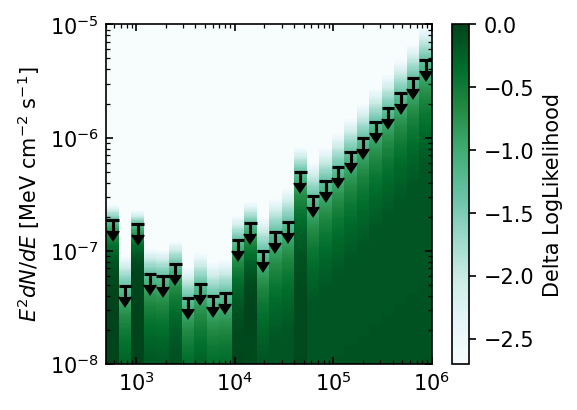

In [4]:
srcname = 'Draco'

sed_path = dSphs_sed_path + '/{}_sed.fits'.format(srcname)
sed = fits.open(sed_path)[1].data


setplot()
ylim=[1e-8,1e-5]
plot_lnlscan(sed, ylim=ylim)
plot_flux_points(sed)
plt.gca().set_ylim(ylim)


# Convert SED to DM space

In [5]:
from scipy import interpolate
from scipy.optimize import minimize, minimize_scalar, fmin
from iminuit import Minuit
import copy




def exctractcirellitable(DMmass,DMchannel,particle,EWcorr):
    '''
    This function returns the energy spectrum in 1/GeV for the particle production from DM annihilation.
    These results come from the PPPC4DM http://www.marcocirelli.net/PPPC4DMID.html
    Relevant tables should be downloaded and stored locally
    
    DMmass: dark matter mass in GeV
    DMchannel: dark matter annihilation channel with EW correction (no EW correction)
    e 4 (2), mu 7 (3), tau 10 (4), bb 13 (7), tt 14 (8), WW 17 (9), ZZ 20 (10), gamma 22 (12), h 23 (13)
    particle: particle produced from the DM annihilation ('gammas' or 'positrons')
    EWcorr: electroweak corrections ('Yes' or 'No')
    '''

    if EWcorr=='Yes':
        listenergies = 179
        energy_vec = np.arange(-8.9,0.05,0.05)
    elif EWcorr=='No':
        listenergies = 180
        energy_vec = np.arange(-8.95,0.05,0.05)
    else:
        print('Error Wrong value for EWcorr, Yes or No')
    
    energy = np.zeros(listenergies)
    fluxDM = np.zeros(listenergies)
    if EWcorr=='No': 
        table = np.loadtxt('particle_data/AtProduction%sEW_%s.dat'%(EWcorr,particle), skiprows=1)
    else:
        table = np.loadtxt('particle_data/AtProduction_%s.dat'%(particle), skiprows=1)
    massvec = []
    for t in range(len(table)):
        if t%listenergies == 0:
            massvec.append(table[t,0])
    massvec = np.array(massvec)
    
    flux = []
    for t in range(len(table)):
        flux.append(table[t,DMchannel])
    
    f = interpolate.interp2d(massvec, energy_vec, flux, kind='linear')

    for t in range(len(energy_vec)):
        fluxDM[t] = f(DMmass,energy_vec[t])
    
    return np.power(10.,energy_vec)*DMmass, fluxDM/(np.log(10.)*np.power(10.,energy_vec)*DMmass)

def func_interpolate(varval,variablevec,funcvec):
    
    result = 0.
    if varval<variablevec[0]:
        result = 0.
    elif varval>variablevec[len(variablevec)-1]:
        result = 0.
    else:
        Log10E_bin = np.log10(variablevec[1])-np.log10(variablevec[0])
        nbin = ( np.log10(varval)-np.log10(variablevec[0]) )/Log10E_bin
        binval = int(nbin)
        result = pow(10.,  np.log10(funcvec[binval]) + (np.log10(funcvec[binval+1])-np.log10(funcvec[binval]))*(np.log10(varval)-np.log10(variablevec[binval]))/(np.log10(variablevec[binval+1])-np.log10(variablevec[binval]))  )

    return result

# NOTE: For alterante DM flux models, replace this function
def flux_DM_prompt(Energy,DMprop,Jfact):
    '''
        This function returns the DM gamma-ray flux in (MeV^-1 cm^-2 s-1)
    '''
    #Precompute dNdE DM
    DMmass = DMprop[0]
    sigmav = DMprop[1]
    DMchannel = DMprop[2]
    EWcorr = DMprop[3]    
    EnergyDM,fluxDM = exctractcirellitable(DMmass,DMchannel,'gammas',EWcorr)
    for t in range(len(EnergyDM)):
        if fluxDM[t]>0.:
            fluxDM[t]=fluxDM[t]
        else:
            fluxDM[t]=1e-30
    
    dNdE = func_interpolate(Energy,EnergyDM,fluxDM)

    return 0.5*(1./(4.*np.pi))*pow(1./DMmass,2.)*Jfact*sigmav*dNdE *(1e-3) #1e-3 converts 1/GeV->1/MeV

def interpolate_Loglike(fluxval,table_norm,table_loglike):
    
    #print(table_norm,table_loglike)
    
    if fluxval>table_norm[len(table_norm)-1]:
        return table_loglikescan[len(table_norm)-1]
    else:
        f = interpolate.interp1d(table_norm,table_loglike, kind='linear')
        return f(fluxval)
    

def funcLogLike(DMprop,table_norm,table_loglike, eref_vec, Jfactor):
    
    LogLike = 0.
    for t in range(len(table_norm)):

        fluxval = flux_DM_prompt(eref_vec[t],DMprop,Jfactor)
        loglike_interp = interpolate.interp1d(table_norm[t],table_loglike[t], bounds_error=False, fill_value='extrapolate')
        
        LogLike += loglike_interp(fluxval)
        
    return -LogLike


def funcLogLike_profJ(DMprop,table_norm,table_loglike, eref_vec, Jfactor, sigmaJ):
    
    fluxvec = np.zeros(len(table_norm))
    for t in range(len(table_norm)):
        fluxvec[t] = flux_DM_prompt(eref_vec[t],DMprop,Jfactor)
        
    def f(par0):
        
        Loglike = 0
        LogLikeJ = -pow((np.log10(Jfactor*par0)-np.log10(Jfactor)),2.)/(2.*sigmaJ*sigmaJ)
        
        for t in range(len(table_norm)):
            fluxval = fluxvec[t]*par0
            
            if fluxval<table_norm[t][len(table_norm[t])-1]:
                Loglike = Loglike + interpolate_Loglike(fluxval,table_norm[t],table_loglike[t])
            else:
                Loglike = Loglike + table_loglike[t][len(table_loglike[t])-1]

        return -Loglike-LogLikeJ


    m=Minuit(f, par0=0.01)
    m.limits = (1e-3, 1e3)
    m.tol=1e-4
    m.errordef=1 
    m.migrad()
    
    Jren_bestfit = m.values["par0"]
    Jren_error = m.errors["par0"]
    
    return m.fval,Jren_bestfit,Jren_error





In [6]:
def convert_sed(sed, Jfactor, sigmaJ=None, EWcorr='Yes', indexDMchannel = 10, 
               mass_vec=np.logspace(0,4,40), sigmav_vec=np.logspace(-28,-22,60)):

    table_refdnde = copy.deepcopy(sed['ref_dnde'])
    table_normscan = copy.deepcopy(sed['norm_scan'])


    #convert table_normscan to units of cm^-2 s^-1 MeV^-1
    for t in range(len(table_refdnde)):
        table_normscan[t] = sed['norm_scan'][t,:]*table_refdnde[t]

    table_loglikescan = copy.deepcopy(sed['dloglike_scan'])

    # Convert MeV to GeV
    eref_vec = copy.deepcopy(sed['e_ref'])/1.e3

    #-------------------------------------------
    # Producing Loglike profiling with sigmav.
    #-------------------------------------------
    
    LogLike_vec = np.zeros(shape=(len(mass_vec),len(sigmav_vec)))
    LogLikeJprof_vec = np.zeros(shape=(len(mass_vec),len(sigmav_vec)))

    for u in range(len(mass_vec)):
        for t in range(len(sigmav_vec)):
            #define list of DM propoerties
            DMprop = [mass_vec[u],sigmav_vec[t],indexDMchannel, EWcorr]
            LogLike_vec[u,t] = -funcLogLike(DMprop,table_normscan,table_loglikescan, eref_vec=eref_vec, Jfactor=Jfactor)
            if sigmaJ!=None:
                LogLikeJprof_vec[u,t] = -funcLogLike_profJ(DMprop,table_normscan,table_loglikescan, eref_vec=eref_vec, Jfactor=Jfactor, sigmaJ=sigmaJ)[0]
            print('sigmav {:.2e} mass {:.2f}'.format(sigmav_vec[t], mass_vec[u]))

    if sigmaJ!=None:
        TS_prior = 2*(LogLikeJprof_vec - LogLikeJprof_vec[-1,0])
        return TS_prior
    else:
        TS_noprior = 2*(LogLike_vec - LogLike_vec[-1,0])
        return TS_noprior

In [7]:
%%time


#Note, running this with 40 mass values and 60 cross swection values can take quite a while, up to a few hours
# Instead for demonstration we will only do 8 mass values and 12 cross-sections. This should take 15-20 minutes
mass_vec =  np.logspace(0,4,8)
sigmav_vec = np.logspace(-28,-22,12)
    

    
# To convert the SED likelihood into DM space, we need to provide all the relevant dm parameters, 
# and the mass and cross ection range we want to scan over
# EWcorr = 'Yes', indexDMchannel = 10 are the relevant terms for the DM flux properties
# if s sigmaJ is provided, the J factor prior will be aplied

# Set to True to run the conversion
if True:
    TS_array = convert_sed(sed, Jfactor =pow(10,18.83), sigmaJ = 0.12, 
                                    EWcorr = 'Yes', indexDMchannel = 10,
                                  mass_vec=mass_vec, sigmav_vec=sigmav_vec)


sigmav 1.00e-28 mass 1.00
sigmav 3.51e-28 mass 1.00
sigmav 1.23e-27 mass 1.00
sigmav 4.33e-27 mass 1.00
sigmav 1.52e-26 mass 1.00
sigmav 5.34e-26 mass 1.00
sigmav 1.87e-25 mass 1.00
sigmav 6.58e-25 mass 1.00
sigmav 2.31e-24 mass 1.00
sigmav 8.11e-24 mass 1.00
sigmav 2.85e-23 mass 1.00
sigmav 1.00e-22 mass 1.00
sigmav 1.00e-28 mass 3.73
sigmav 3.51e-28 mass 3.73
sigmav 1.23e-27 mass 3.73
sigmav 4.33e-27 mass 3.73
sigmav 1.52e-26 mass 3.73
sigmav 5.34e-26 mass 3.73
sigmav 1.87e-25 mass 3.73
sigmav 6.58e-25 mass 3.73
sigmav 2.31e-24 mass 3.73
sigmav 8.11e-24 mass 3.73
sigmav 2.85e-23 mass 3.73
sigmav 1.00e-22 mass 3.73
sigmav 1.00e-28 mass 13.89
sigmav 3.51e-28 mass 13.89
sigmav 1.23e-27 mass 13.89
sigmav 4.33e-27 mass 13.89
sigmav 1.52e-26 mass 13.89
sigmav 5.34e-26 mass 13.89
sigmav 1.87e-25 mass 13.89
sigmav 6.58e-25 mass 13.89
sigmav 2.31e-24 mass 13.89
sigmav 8.11e-24 mass 13.89
sigmav 2.85e-23 mass 13.89
sigmav 1.00e-22 mass 13.89
sigmav 1.00e-28 mass 51.79
sigmav 3.51e-28 mass 51.7

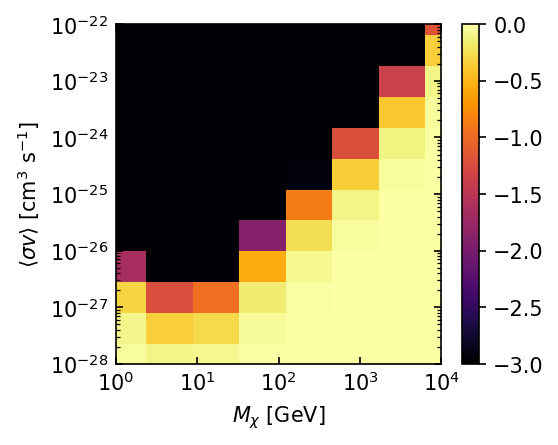

In [8]:
# plot TS profile
try:
    setplot()
    ax=plt.gca()

    plt.loglog()
    img = plt.pcolormesh(mass_vec,sigmav_vec,TS_array.T, cmap="inferno", vmin=-3)

    levels = TS_array.max() - np.asarray([11.8,6.17,2.3])
    if(TS_array.max()>2.3):
        plt.contour(mass_vec,sigmav_vec,TS_array.T,levels=levels,colors='limegreen',linestyles=["-.",'--',"-"], linewidths=3*[1],alpha=1)

    plt.xlim(1, 1e4)
    plt.ylim(1e-28, 1e-22)
    plt.xticks(np.logspace(0,4,5))

    cbr = plt.colorbar(img)

    ax.set_xlabel('$M_{\chi}$ [GeV]')
    ax.set_ylabel(r'$\left<\sigma v\right>$ [cm$^{3}$ s$^{-1}$]')
except Exception as e:
    print(e)


## Stack TS profiles

Here we will use the precomputed TS profiles to demonstrate creating a combined TS profile and obtaining upper limits

#### Subsample lists

In [10]:

measured = ['Aquarius_2',
'Bootes_2',
'Canes_V1',
'Canes_V2',
'Carina',
'Carina_2',
'Berenices',
'Draco',
'Eridanus_2',
'Fornax',
'Hercules',
'Horologium_1',
'Hydrus_1',
'Leo_1',
'Leo_2',
'Leo_4',
'Leo_5',
'Pegasus_3',
'Pisces_2',
'Reticulum_2',
'Sagittarius_2',
'Segue_1',
'Sextans',
'Tucana_2',
'Tucana_4',
'Ursa_Major_1',
'Ursa_Major_2',
'Ursa_Minor',
'Draco_2',
'Grus_1']

benchmark = ['Aquarius_2',
'Bootes_2',
'Canes_V1',
'Canes_V2',
'Carina',
'Carina_2',
'Carina_3',
'Berenices',
'Draco',
'Eridanus_2',
'Fornax',
'Hercules',
'Horologium_1',
'Hydrus_1',
'Leo_1',
'Leo_2',
'Leo_4',
'Leo_5',
'Pegasus_3',
'Phoenix_2',
'Pisces_2',
'Reticulum_2',
'Sagittarius_2',
'Segue_1',
'Sextans',
'Tucana_2',
'Tucana_4',
'Ursa_Major_1',
'Ursa_Major_2',
'Ursa_Minor',
'Bootes_4',
'Centaurus_1',
'Cetus_2',
'Cetus_3',
'Columba_1',
'Draco_2',
'Grus_1',
'Grus_2',
'Pictor_1',
'Pictor_2',
'Reticulum_3',
'Tucana_5']

inclusive = ['Antlia_2',
'Aquarius_2',
'Bootes_1',
'Bootes_2',
'Bootes_3',
'Canes_V1',
'Canes_V2',
'Carina',
'Carina_2',
'Carina_3',
'Berenices',
'Crater_2',
'Draco',
'Eridanus_2',
'Fornax',
'Hercules',
'Horologium_1',
'Hydrus_1',
'Leo_1',
'Leo_2',
'Leo_4',
'Leo_5',
'Pegasus_3',
'Phoenix_2',
'Pisces_2',
'Reticulum_2',
'Sagittarius',
'Sagittarius_2',
'Segue_1',
'Sextans',
'Tucana_2',
'Tucana_4',
'Ursa_Major_1',
'Ursa_Major_2',
'Ursa_Minor',
'Willman_1',
'Bootes_4',
'Centaurus_1',
'Cetus_2',
'Cetus_3',
'Columba_1',
'Draco_2',
'Grus_1',
'Grus_2',
'Horologium_2',
'Pictor_1',
'Pictor_2',
'Reticulum_3',
'Tucana_5',
'Virgo_1']

In [11]:
data = pd.read_csv(dSphs_csv_path + '/dSphs.csv')

Text(0, 0.5, '$\\left<\\sigma v\\right>$ [cm$^{3}$ s$^{-1}$]')

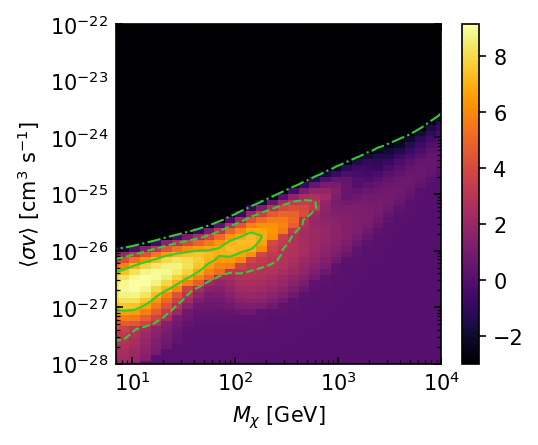

In [12]:
channelname='bb'
prior=True


# Be sure the mass and cross section arrays are the appropriate size
mass_vec =  np.logspace(0,4,40)
sigmav_vec = np.logspace(-28,-22,60)


srclist =benchmark


ts_dict = {}
summed = 0

for srcname in srclist:
    if prior:
        ts_file = dSphs_TS_prof_path + '{}_Jprior_{}.npy'.format(srcname, channelname)
    else:
        ts_file = dSphs_TS_prof_path + '{}_noprior_{}.npy'.format(srcname, channelname)
    if os.path.exists(ts_file):
        tsarray = np.load(ts_file)
        summed += tsarray
        ts_dict[srcname] = tsarray.max()

    else:
        print(tsarray + " does not exist")

setplot()
plt.loglog()
img = plt.pcolormesh(mass_vec,sigmav_vec,summed.T, cmap="inferno", vmin=-3)#, edgecolors='white', linewidth=0.005)

levels = summed.max() - np.asarray([11.8,6.17,2.3])
if(summed.max()>2.3):
    plt.contour(mass_vec[:],sigmav_vec,summed.T[:,:],levels=levels,colors='limegreen',linestyles=["-.",'--',"-"], linewidths=3*[1],alpha=1)

plt.ylim(1e-28, 1e-22)

if channelname=='bb':
    plt.xlim(7, 1e4)
    plt.xticks(np.logspace(1,4,4))
else:
    plt.xlim(1, 1e4)
    plt.xticks(np.logspace(0,4,5))
    
cbr = plt.colorbar(img)

plt.gca().set_xlabel('$M_{\chi}$ [GeV]')
plt.gca().set_ylabel(r'$\left<\sigma v\right>$ [cm$^{3}$ s$^{-1}$]')

## Get UL from Profile Stack

In [13]:

def get_UL(z,  xs, ys,  coeff=2.71):
    ''' calculates upper limit (to the right)'''
    x, y, ULs = [],[],[]

    
    for i,x_val in enumerate(xs):
        min_idx = z[:,i].argmax()
        #print('{:.2f} {} {:2e}'.format(x_val, min_idx, ys[min_idx]))
        zcut = z[:,i].max()-coeff
        f = interpolate.interp1d(z[:,i][min_idx:], ys[min_idx:], bounds_error=False, fill_value='extrapolate')

        idx = (np.abs(z[:,i]-(z[:,i].max()-coeff))[min_idx:].argmin()+min_idx)
        if z[:,i].min()> z[:,i].max()-coeff:
            ULs.append(min(ys))
            x.append(x_val)
            y.append(min(ys))

        else:

            ul = f(z[:,i].max()-coeff)
            ULs.append(ul)
            x.append(x_val)
            y.append(ys[np.argmax(z[:,i])])
        
    return x, ULs, y


(1e-27, 1e-23)

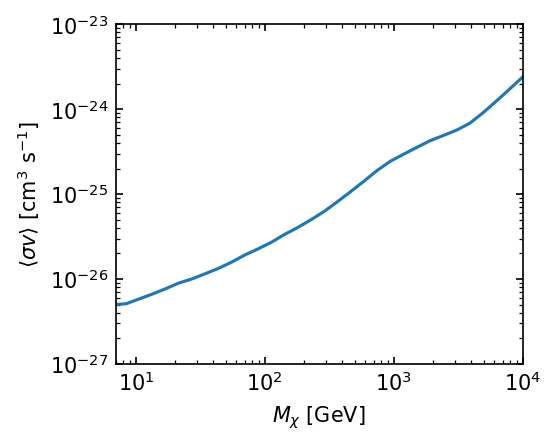

In [14]:
setplot()
plt.loglog()
colors = plt.get_cmap("tab10")

xs, ulsamp, y = get_UL(summed.T, mass_vec,  sigmav_vec)

plt.plot(xs, ulsamp)
    
plt.xlabel('$M_{\chi}$ [GeV]')
plt.ylabel(r'$\left<\sigma v\right>$ [cm$^{3}$ s$^{-1}$]')

if channelname=='bb':
    plt.xlim(7, 1e4)
elif channelname=='tau':
    plt.xlim(1,1e4)
    
plt.ylim(1e-27, 1e-23)

## Generate sample of blank field stacks

In [15]:
import time
from IPython.display import clear_output

In [16]:

def get_time(start):
    elap_time = time.time() - start
    if elap_time <60:
        print('{:.1f} sec'.format(elap_time))
    if elap_time >= 60 and elap_time <3600:
        print('{:.1f} min'.format(elap_time/60))
    if elap_time >= 3600:
        hr = elap_time // 3600
        minutes = (elap_time % 3600)/60
        print('{:.0f} hr {:.1f} min'.format(hr, minutes))

### This step generates the sets of blank fields stacks and takes ~1 min for a set of 500 iterations

In [17]:
blank_field_df = pd.read_csv(blank_field_csv_path + '/blank_fields.csv')

In [22]:
iters=5000

size=len(srclist)

TS_vals_prior=[]
TS_vals_noprior=[]

blank_stacks_prior = []
blank_stacks_noprior = []



start = time.time()
for sim in range(iters):
    #dictionary of ts values and arrays for each iteration
    iter_ts = {}
    iter_ts_array = {}

    summed_noprior=np.zeros((len(mass_vec), len(sigmav_vec)))
    summed_wprior=np.zeros((len(mass_vec), len(sigmav_vec)))

    if (sim+1)%50==0:
        get_time(start)
        print("Iter: {}/{}".format(sim+1, iters))
        try:
            clear_output(wait=True)
        except:
            if sim==0:
                print("clear output failed")
    # Generate stack of blank fields
    field_rand_gen = blank_field_df.sample(size)['Name']
    for i, srcname in enumerate(srclist):
        field =  field_rand_gen.iloc[i]


        TS_file_prior_path = blank_TS_prof_path+'/{}/{}_{}_Jprior_{}.npy'.format(srcname,srcname,field,channelname)
        TS_prior = np.load(TS_file_prior_path)

        TS_file_noprior_path = blank_TS_prof_path+'/{}/{}_{}_noprior_{}.npy'.format(srcname,srcname,field,channelname)
        TS_noprior = np.load(TS_file_noprior_path)

        summed_noprior+= TS_noprior
        summed_wprior+= TS_prior



    # store TS vals and stacks
    TS_vals_noprior.append(summed_noprior.max())
    TS_vals_prior.append(summed_wprior.max() )

    blank_stacks_noprior.append(summed_noprior)
    blank_stacks_prior.append(summed_wprior)


TS_vals_noprior = np.asarray(TS_vals_noprior)    
TS_vals_prior = np.asarray(TS_vals_prior)    
blank_stacks_noprior = np.asarray(blank_stacks_noprior)    
blank_stacks_prior = np.asarray(blank_stacks_prior)

    


8.2 min
Iter: 5000/5000


### Create TS vs $M_{\chi}$ plot

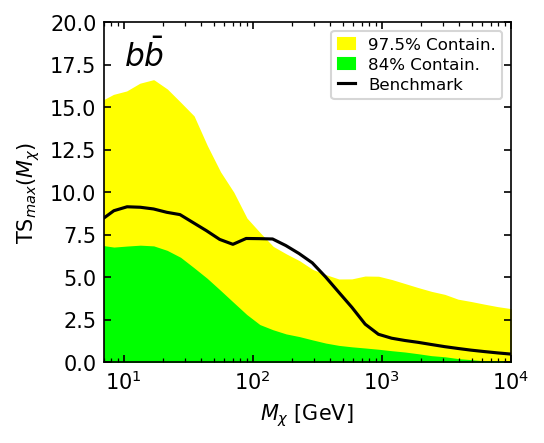

In [23]:
prior='prior'

ax, fig = setplot()
plt.semilogx()

ts_v_m_stack = []
for mi, mass in enumerate(mass_vec):
    ts_v_m_stack.append(summed[mi][np.argmax(summed[mi])])

ts_v_m_blanks = []
for j in range(iters):
    ts_vals = []
    if prior=='prior':
        test = blank_stacks_prior[j]
    elif prior=='noprior':
        test = blank_stacks_noprior[j]

    for i, mass in enumerate(mass_vec):

        ts = test[i][np.argmax(test[i])]
        ts_vals.append(ts)
    
    ts_v_m_blanks.append(ts_vals)
    
ts_v_m_blanks = np.asarray(ts_v_m_blanks)


plt.fill_between(mass_vec, np.percentile(ts_v_m_blanks, 97.5, axis=0),  label = '97.5% Contain.',alpha=1, color='yellow')
plt.fill_between(mass_vec, np.percentile(ts_v_m_blanks, 84, axis=0),  label = '84% Contain.', alpha=1, color='lime')
plt.plot(mass_vec, ts_v_m_stack, color='k', label='Benchmark')


if channelname=='bb':
    plt.xlim(7, 1e4)
    ax.text(0.05, 0.95, r'$b\bar{b}$', horizontalalignment='left',
     verticalalignment='top', transform=ax.transAxes, fontsize=15)
elif channelname=='tau':
    plt.xlim(1, 1e4)
    ax.text(0.05, 0.95, r'$\tau^+\tau^-$', horizontalalignment='left',
     verticalalignment='top', transform=ax.transAxes, fontsize=15)
    
plt.ylim(0,20)
plt.xlabel(r'$M_{\chi}$ [GeV]')
plt.ylabel(r'TS$_{max}(M_{\chi})$')
plt.legend(fontsize=8,  handlelength=1, loc='upper right', labelspacing=.3, ncol=1, columnspacing=0.5)

### Get ULs for the blank stacks

In [24]:
%%time 
useprior='prior'

uls=[]
start=time.time()
for i in range(iters):
    
    if useprior=='prior':
        array = blank_stacks_prior[i]
    else:
        array = blank_stacks_noprior[i]
    xs, uli, _ = get_UL(array.T, mass_vec, sigmav_vec)
    uls.append(uli)
    if (1+i) %100 ==0:
        get_time(start)
        print('{}/{}'.format(i+1, iters))
        #start = time.time()
        clear_output(wait=True)
    
uls = np.asarray(uls)
highlim_wprior, lowlim_wprior = np.quantile(uls,q=1-0.05/2,axis=0), np.quantile(uls,q=0.05/2,axis=0)
highlim_wprior68, lowlim_wprior68 = np.quantile(uls,q=1-0.32/2,axis=0), np.quantile(uls,q=0.32/2,axis=0)
median = np.median(uls, axis=0)

CPU times: user 44.2 s, sys: 168 ms, total: 44.4 s
Wall time: 45.1 s


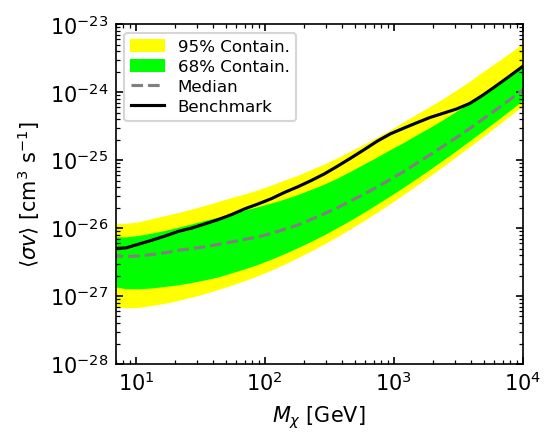

In [25]:
ax, fig = setplot()
plt.loglog()
plt.xlabel('$M_{\chi}$ [GeV]')
plt.ylabel(r'$\left<\sigma v\right>$ [cm$^{3}$ s$^{-1}$]')
plt.fill_between(mass_vec,lowlim_wprior, highlim_wprior, label = '95% Contain.', alpha=1, color='yellow')
plt.fill_between(mass_vec,lowlim_wprior68, highlim_wprior68, label = '68% Contain.', alpha=1, color='lime')

plt.plot(mass_vec,median, label = 'Median', alpha=1, color='grey', ls='--')
plt.plot(xs, ulsamp , label='Benchmark', color='k')

if channelname=='bb':
    plt.xlim(7, 1e4)
elif channelname=='tau':
    plt.xlim(1,1e4)
    
plt.ylim(1e-28, 1e-23)
plt.legend(fontsize=8, columnspacing=0.65, labelspacing=.3, loc='upper left')